# Day 38 — Ask the Neighbours
## k-Nearest Neighbours

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

The first model in this course that **fits no equation at all**. It memorises the data
and answers by looking things up.

| Part | What we do |
|---|---|
| **1** | The algorithm, and what k does |
| **2** | Distance decides everything — the scaling trap |
| **3** | Choosing k, and the two things KNN is bad at |

| | learns | keeps | training cost | prediction cost |
|---|---|---|---|---|
| Linear / logistic regression | w and b | a few numbers | once | instant |
| **k-Nearest Neighbours** | **nothing** | **the whole dataset** | **none** | **a search, every time** |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.metrics import r2_score

import warnings; warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("ready")

ready


---
# Part 1 — The algorithm

### Four steps

1. **Pick k** — how many neighbours get a vote
2. **Measure the distance** from the new row to every row you stored
3. **Take the k closest** and look up what happened to them
4. **Vote** — majority wins (or average, for regression)

That is the entire model. Here is the data we will use: **600 loan applications**, with
income in rupees and length of service in years.

In [2]:
r = np.random.default_rng(3800)
N = 600

income         = r.normal(68000, 26000, N).clip(18000, 200000).round(0)
years_employed = r.uniform(0, 20, N).round(1)

z = -5.9 + 0.000026*income + 0.34*years_employed + r.normal(0, 0.45, N)
approved = (r.uniform(0, 1, N) < sigmoid(z)).astype(int)

loans = pd.DataFrame({"income": income, "years_employed": years_employed,
                      "approved": approved})
X, y = loans[["income", "years_employed"]], loans.approved

print(f"rows {N}   approved {int(y.sum())}   rate {y.mean():.4f}")
print(f"baseline ('reject everybody') {1 - y.mean():.4f}")
print()
print(f"income spread (sd) : {income.std():>9,.0f}")
print(f"years  spread (sd) : {years_employed.std():>9.2f}")
print(f"ratio              : {income.std()/years_employed.std():>9,.0f} : 1")
loans.head()

rows 600   approved 242   rate 0.4033
baseline ('reject everybody') 0.5967

income spread (sd) :    26,041
years  spread (sd) :      5.79
ratio              :     4,496 : 1


,income,years_employed,approved
0,82815.0,13.4,1
1,32419.0,12.5,0
2,91053.0,9.5,1
3,73899.0,6.9,0
4,54541.0,2.0,0


In [3]:
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X, y)              # this just stores the data
print("stored rows:", model.n_samples_fit_)
print("prediction for one new applicant:",
      model.predict([[62000, 11.0]])[0])

stored rows: 600
prediction for one new applicant: 0


## What k controls

`k = 1` asks one neighbour. `k = 101` asks a hundred and one. Watch what that does to
the boundary between approve and reject.

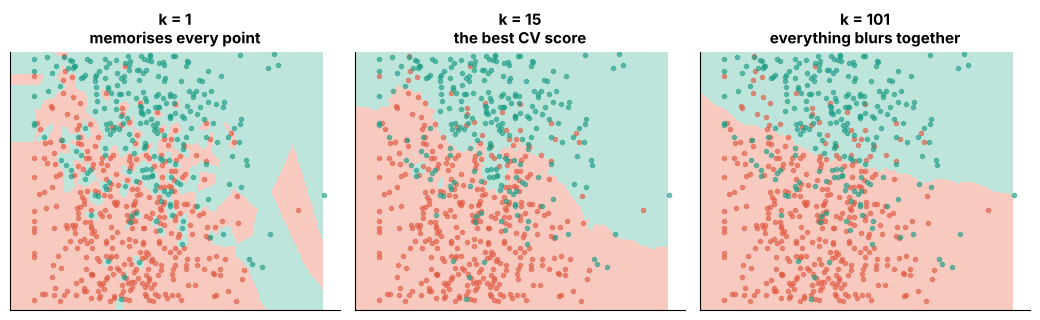

In [4]:
Xs = StandardScaler().fit_transform(X.values)
gx, gy = np.meshgrid(np.linspace(-2.4, 3.6, 220), np.linspace(-1.8, 1.8, 220))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
for ax, k, note in zip(axes, [1, 15, 101],
                       ["memorises every point", "the best CV score",
                        "everything blurs together"]):
    m = KNeighborsClassifier(k).fit(Xs, y)
    ax.contourf(gx, gy, m.predict(grid).reshape(gx.shape),
                levels=[-0.5, 0.5, 1.5], colors=["#F7C9BF", "#BEE5DB"])
    ax.scatter(Xs[y == 0, 0], Xs[y == 0, 1], s=9, c="#E05C45", alpha=0.6)
    ax.scatter(Xs[y == 1, 0], Xs[y == 1, 1], s=9, c="#1F9E86", alpha=0.6)
    ax.set_title(f"k = {k}\n{note}", fontsize=11, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**k = 1** carves an island round every single point — that is memorising, and Day 36
told you what it costs. **k = 101** asks so many neighbours that the local detail
disappears.

Somewhere in between is the right answer, and Part 3 finds it properly.

---
# Part 2 — Distance decides everything

Distance is just Pythagoras:

```
distance = sqrt( (income_A - income_B)² + (years_A - years_B)² )
```

And that is the problem. Take two applicants:

```
A:  income 44,000  ·  18 years
B:  income 44,200  ·   0 years

distance = sqrt(200² + 18²) = 200.8
```

**Eighteen years of service moved the distance by 0.8.** Income is measured in numbers
about 4,500 times larger, so it swamps the other column completely.

The years column is still in the data. The model simply cannot hear it.

## One applicant, with and without scaling

Here is a real applicant from our data: **income ₹44,000, 18 years employed**.
Let us find her five nearest neighbours twice.

In [5]:
XL = X.values
sc = StandardScaler().fit(XL)
q = np.array([44000.0, 18.0])

d_raw = np.sqrt(((XL - q)**2).sum(1))
d_sc  = np.sqrt(((sc.transform(XL) - sc.transform(q.reshape(1, -1)))**2).sum(1))

for name, d in [("ON THE RAW NUMBERS", d_raw), ("AFTER SCALING", d_sc)]:
    idx = np.argsort(d)[:5]
    print(f"{name}")
    print(f"   {'income':>9}{'years':>8}{'approved':>10}{'distance':>11}")
    for i in idx:
        print(f"   {XL[i,0]:>9,.0f}{XL[i,1]:>8.1f}{y.values[i]:>10}{d[i]:>11.4f}")
    v = int(y.values[idx].sum())
    print(f"   vote {v} of 5  ->  "
          f"{'APPROVE' if v > 2 else 'REJECT'}\n")

ON THE RAW NUMBERS
      income   years  approved   distance
      43,938     3.6         0    63.6503
      43,892     2.6         0   109.0924
      44,200    11.6         0   200.1024
      44,209     0.8         0   209.7066
      44,275    12.1         0   275.0633
   vote 0 of 5  ->  REJECT

AFTER SCALING
      income   years  approved   distance
      43,643    18.3         1     0.0536
      42,643    18.1         1     0.0549
      41,617    18.0         1     0.0915
      48,347    17.8         1     0.1705
      48,522    18.1         1     0.1745
   vote 5 of 5  ->  APPROVE



### Read the `years` column in each table

**On the raw numbers** the five nearest all have income within ₹300 of hers — and years
of service of **3.6, 2.6, 11.6, 0.8, 12.1**. The model found five people on the same
salary with completely different careers. Vote: **0 of 5 → REJECT**.

**After scaling** they have years of **18.3, 18.1, 18.0, 17.8, 18.1** — the same salary
*and* the same length of service. Vote: **5 of 5 → APPROVE**.

Same applicant. Same data. Same k. **One line of code decides whether she gets the loan.**

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)

print(f"{'k':>5}{'raw numbers':>14}{'scaled':>10}{'gain':>9}")
print("-" * 38)
for k in [1, 5, 15, 25]:
    raw = cross_val_score(KNeighborsClassifier(k), X, y, cv=cv).mean()
    scd = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)),
                          X, y, cv=cv).mean()
    print(f"{k:>5}{raw:>14.4f}{scd:>10.4f}{scd-raw:>+9.4f}")
print("-" * 38)
print(f"{'':>5}{'guessing:':>14}{1-y.mean():>10.4f}")

    k   raw numbers    scaled     gain
--------------------------------------
    1        0.5450    0.7317  +0.1867
    5        0.5650    0.7883  +0.2233


   15        0.5800    0.8200  +0.2400


   25        0.5783    0.8133  +0.2350
--------------------------------------
          guessing:    0.5967


### Unscaled, KNN scores *below* the baseline at every k we tried

0.5450, 0.5650, 0.5800, 0.5783 — all worse than simply rejecting everybody (0.5967).
Scaled, the same model reaches **0.8200**.

**One line of code is worth 24 points of accuracy.**

So KNN always goes in a Pipeline:

In [7]:
knn = Pipeline([("scale", StandardScaler()),
                ("model", KNeighborsClassifier(n_neighbors=15))])

print(f"cross-validated accuracy: {cross_val_score(knn, X, y, cv=cv).mean():.4f}")

cross-validated accuracy: 0.8200


The Pipeline matters for the Day 36 reason too: the scaler is refitted **inside every
fold**, so no fold ever sees the rows it is about to be scored on.

> **If you remember one thing from today:** KNN without a scaler is not a model, it is
> the column with the biggest numbers.

*(StandardScaler is the usual choice. Use `MinMaxScaler` if your columns have hard
limits, `RobustScaler` if a few extreme values would otherwise stretch everything.)*

---
# Part 3 — Choosing k, and two weaknesses

## Cross-validate k. Do not guess it.

In [8]:
ks = [1, 3, 5, 9, 15, 21, 25, 31, 41, 51, 75, 101]
tr, te = [], []
print(f"{'k':>5}{'studied':>10}{'CV':>10}{'gap':>9}")
print("-" * 34)
for k in ks:
    res = cross_validate(make_pipeline(StandardScaler(), KNeighborsClassifier(k)),
                         X, y, cv=cv, return_train_score=True)
    a, b = res["train_score"].mean(), res["test_score"].mean()
    tr.append(a); te.append(b)
    print(f"{k:>5}{a:>10.4f}{b:>10.4f}{a-b:>+9.4f}")

best = ks[int(np.argmax(te))]
print(f"\nbest k = {best}  ->  CV {max(te):.4f}")
print(f"logistic regression, for comparison: "
      f"{cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, y, cv=cv).mean():.4f}")

    k   studied        CV      gap
----------------------------------


    1    1.0000    0.7317  +0.2683


    3    0.8867    0.7900  +0.0967


    5    0.8467    0.7883  +0.0583


    9    0.8250    0.8000  +0.0250
   15    0.8313    0.8200  +0.0112


   21    0.8250    0.8100  +0.0150


   25    0.8208    0.8133  +0.0075


   31    0.8171    0.8117  +0.0054
   41    0.8104    0.8000  +0.0104


   51    0.8096    0.8033  +0.0062


   75    0.8146    0.8083  +0.0063
  101    0.8071    0.8083  -0.0013

best k = 15  ->  CV 0.8200
logistic regression, for comparison: 0.8083


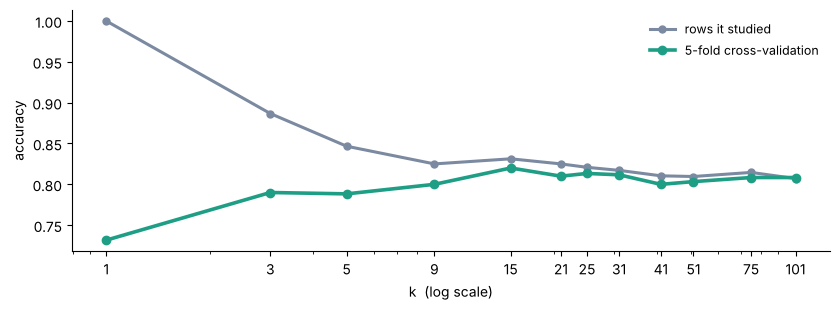

In [9]:
plt.figure(figsize=(8.5, 3.2))
plt.plot(ks, tr, "-o", color="#7B8AA1", lw=2.2, ms=5, label="rows it studied")
plt.plot(ks, te, "-o", color="#1F9E86", lw=2.6, ms=6, label="5-fold cross-validation")
plt.xscale("log"); plt.xticks(ks, ks)
plt.xlabel("k  (log scale)"); plt.ylabel("accuracy")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### How to read it

**k = 1:** 1.0000 on its own rows, **0.7317** on new ones — a gap of 0.27. Every point is
its own nearest neighbour, so it cannot be wrong about itself. The clearest picture of
overfitting you will see this term.

**k = 101:** 0.8083, below the best. Too many neighbours, most of them not really similar.

**k = 15 won, at 0.8200** — and beat logistic regression's 0.8083 on this data.

Two practical notes: use an **odd k** for two classes so a vote cannot tie, and
`weights="distance"` makes closer neighbours count for more.

√n is a common rule of thumb (≈ 24 here) but it is only a starting point. Cross-validate.

## Weakness 1: the bill arrives at prediction time

In [10]:
print(f"{'rows stored':>14}{'KNN fit':>12}{'KNN predict':>14}{'logistic predict':>19}")
print("-" * 60)
for n in [1000, 10000, 100000]:
    rr = np.random.default_rng(1)
    Xb, yb = rr.normal(0, 1, (n, 10)), rr.integers(0, 2, n)
    Xq = rr.normal(0, 1, (1000, 10))

    t = time.perf_counter(); m = KNeighborsClassifier(15).fit(Xb, yb)
    fit_t = (time.perf_counter() - t) * 1000
    t = time.perf_counter(); m.predict(Xq)
    knn_t = (time.perf_counter() - t) * 1000
    l = LogisticRegression(max_iter=2000).fit(Xb, yb)
    t = time.perf_counter(); l.predict(Xq)
    log_t = (time.perf_counter() - t) * 1000

    print(f"{n:>14,}{fit_t:>10.1f}ms{knn_t:>12.1f}ms{log_t:>17.2f}ms")

   rows stored     KNN fit   KNN predict   logistic predict
------------------------------------------------------------
         1,000       1.6ms        22.2ms             0.31ms
        10,000      10.4ms       116.9ms             0.30ms


       100,000     169.9ms       519.4ms             0.41ms


**Training is free because nothing happens.** Then every prediction searches the whole
dataset. At 100,000 stored rows, predicting 1,000 rows takes about **475 ms** against
logistic regression's **0.3 ms** — roughly 1,600 times slower.

## Weakness 2: it falls apart on wide data

Here is data where **only the first two columns carry any signal**. Everything else is
noise — and noise still counts towards the distance.

In [11]:
print(f"{'columns':>9}{'nearest':>10}{'farthest':>10}{'ratio':>8}{'KNN accuracy':>15}")
print("-" * 52)
rr = np.random.default_rng(5)
for d in [2, 5, 10, 50, 200, 1000]:
    P = rr.normal(0, 1, (500, d)); q = rr.normal(0, 1, (1, d))
    dd = np.sqrt(((P - q)**2).sum(1))
    lab = (P[:, 0] + P[:, 1] > 0).astype(int)     # only columns 0 and 1 matter
    acc = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
                          P, lab, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    print(f"{d:>9}{dd.min():>10.3f}{dd.max():>10.3f}{dd.max()/dd.min():>8.2f}{acc:>15.4f}")

  columns   nearest  farthest   ratio   KNN accuracy
----------------------------------------------------
        2     0.088     3.577   40.64         0.9660
        5     0.621     5.924    9.54         0.9220
       10     2.491     7.033    2.82         0.8440


       50     7.791    13.251    1.70         0.7180


      200    16.576    21.939    1.32         0.6340
     1000    41.173    46.673    1.13         0.5680


### The curse of dimensionality

At 2 columns the farthest point is **40 times** further away than the nearest. At 1,000
columns it is **1.13 times** — everything is about as far away as everything else, so
"nearest" stops meaning anything, and accuracy falls from **0.9660 to 0.5680**.

This is why KNN is a bad choice for text, images, or any wide dataset.

## It does regression too

Swap the vote for an average: `KNeighborsRegressor`.

    k   studied R2   held back R2
---------------------------------
    1       1.0000         0.9161
    3       0.9353         0.9208
    5       0.9153         0.9024
   10       0.8896         0.8872
   20       0.8252         0.8108
   40       0.7027         0.6880


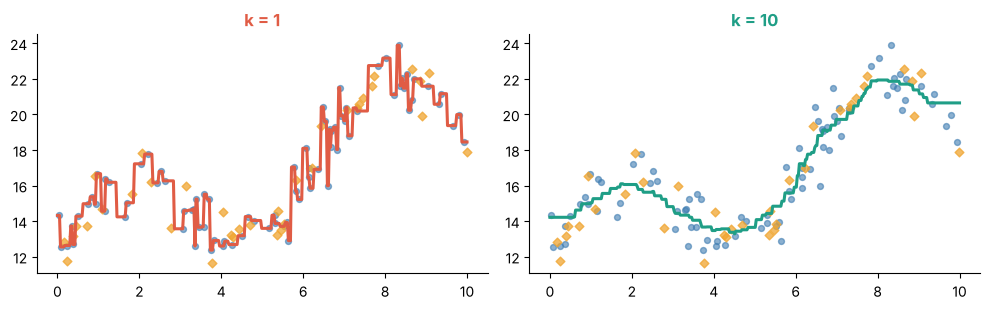

In [12]:
rr = np.random.default_rng(3810); M = 120
xr = np.sort(rr.uniform(0, 10, M))
yr = 12 + 3.0*np.sin(xr) + 0.9*xr + rr.normal(0, 1.1, M)
xa, xb, ya, yb = train_test_split(xr.reshape(-1, 1), yr, test_size=0.3, random_state=0)

print(f"{'k':>5}{'studied R2':>13}{'held back R2':>15}")
print("-" * 33)
for k in [1, 3, 5, 10, 20, 40]:
    m = KNeighborsRegressor(k).fit(xa, ya)
    print(f"{k:>5}{r2_score(ya, m.predict(xa)):>13.4f}{r2_score(yb, m.predict(xb)):>15.4f}")

line = np.linspace(0, 10, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, k, c in zip(axes, [1, 10], ["#E05C45", "#1F9E86"]):
    m = KNeighborsRegressor(k).fit(xa, ya)
    ax.scatter(xa, ya, s=18, c="#3E7CB1", alpha=0.6)
    ax.scatter(xb, yb, s=20, c="#F0A530", marker="D", alpha=0.75)
    ax.plot(line, m.predict(line), color=c, lw=2.2)
    ax.set_title(f"k = {k}", fontweight="bold", color=c)
plt.tight_layout(); plt.show()

The **steps** in the k = 1 line are the model copying single points. There is no
equation, so there is no smooth curve — just a staircase between the stored values.

k = 1: studied R² **1.0000**, held back **0.9161**. k = 10: **0.8896** and **0.8872** —
the gap almost gone.

---
# The four habits

| | | |
|---|---|---|
| **1** | **Always scale** | unscaled it scored below guessing |
| **2** | **Choose k by cross-validation** | k = 1 memorises, k = 101 blurs |
| **3** | **Keep the columns few** | at 1,000 columns it is a coin flip |
| **4** | **Watch the clock** | no training, but every prediction is a search |

## When to reach for it

| good fit | bad fit |
|---|---|
| few columns, plenty of rows | many columns — text, images, anything wide |
| the boundary is irregular and no equation would describe it | very large data, or predictions needed in milliseconds |
| you want a baseline in two lines of code | you must explain *why* to a regulator or customer |
| "who is most like this customer?" | missing values, which have no distance |

## Four numbers from today

- **0 of 5 → 5 of 5** — the same applicant, rejected on raw numbers and approved after scaling
- **0.5800 → 0.8200** — KNN at k = 15 before and after one line of `StandardScaler`;
  "reject everybody" scores 0.5967
- **1.0000 / 0.7317** — k = 1 on the rows it studied, and on rows it had never seen
- **40.64 → 1.13** — farthest ÷ nearest as columns go from 2 to 1,000, and accuracy falls
  to 0.5680

---

**Next:** decision trees — a model that explains itself.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*